# 17 — Atlas completo das dez entradas e dos 45 pares

**Pergunta:** como cada entrada e cada par reagem a mudanças graduais de −50% a +50%, em passos de 5%? Este atlas lê os quatro CSVs produzidos pelo [notebook 09](09_percentuais_guiados.ipynb), verifica sua cobertura e cria figuras detalhadas de **todas** as dez entradas e **todos** os 45 pares. Os mapas e os índices permitem encontrar qualquer combinação sem depender de um exemplo escolhido para o relatório.

## Ordem de execução

1. Use o Booster congelado em `models/` e execute o notebook 09 para gerar as quatro tabelas percentuais. Se essas tabelas já estiverem em `results/tables/`, prossiga diretamente para o passo 2. O notebook 00 serve para conferir o artefato no fluxo padrão; retreinamento é uma opção explícita e separada.
2. Abra este notebook a partir da raiz do repositório ou da pasta `notebooks/` e execute todas as células.
3. Consulte os índices ao final e abra os PNGs em `results/figures/atlas_variaveis/` e `results/figures/atlas_pares/`. As tabelas completas permanecem em `results/tables/`.

O modelo fica congelado: este notebook **não retreina** nem recalcula os cenários. Ele analisa e apresenta todos os resultados já executados no 09.

## 1. O que significam as duas famílias de experimentos?

| Família | Intervenção | Há rótulo observável para avaliar desempenho? | Leituras legítimas |
|---|---|---|---|
| **Mix da população** | Reponderar linhas inteiras do holdout, mantendo cada vetor de entradas, seu rótulo observado e o score original juntos | **Sim.** A nova população hipotética é uma mistura diferente dos mesmos perfis observados | PSI, Brier, AUC ROC, PR-AUC trapezoidal, KS do modelo e tamanho efetivo da amostra (ESS) |
| **Valor da entrada** | Multiplicar um ou dois valores entregues ao modelo por `1+r`, com regras de arredondamento para contagens | **Não há Y contrafactual observado** para uma pessoa cujo atributo real mudou. Interprete como erro ou perturbação da medição, não como nova performance populacional | PSI da entrada, movimento do score, decisões que atravessam 0,50 e suporte dos valores gerados |

No **mix univariado**, `r` é a variação relativa pedida na proporção do grupo alto; no **valor univariado**, `r` é a variação pedida no valor da coluna. Em pares, os sinais `++`, `+-`, `-+` e `--` indicam a direção solicitada para a primeira e a segunda variável, sempre com magnitudes 5, 10, …, 50%. A mudança **realizada** pode diferir da solicitada, sobretudo em contagens inteiras, limites e grupos pequenos.

**PSI** (Population Stability Index) descreve a mudança de uma distribuição: `Σ(qᵢ−pᵢ) ln(qᵢ/pᵢ)`, com `pᵢ` e `qᵢ` representando as proporções nos mesmos bins de referência. **KS do modelo** é outra quantidade: `maxₜ[TPR(t)−FPR(t)]`, a maior separação entre as taxas de verdadeiros e falsos positivos ao variar o limiar do score. **KS de uma variável**, quando usado como distância entre distribuições, também é diferente do KS do modelo. PSI **não é porcentagem** nem há um valor universal que aprove um modelo.

Nas figuras, `Δ métrica = métrica do cenário − métrica de referência`. Brier maior indica maior erro; AUC ROC, PR-AUC e KS do modelo menores indicam perda de discriminação. O valor absoluto `|Δ|` nos mapas resume o **tamanho** da mudança observada, independentemente do sentido; confira a curva detalhada para ver se houve melhoria ou deterioração. Recall e precisão no corte 0,50 permanecem nas tabelas de origem como descritores; nenhuma métrica é usada como critério automático de parada.

In [1]:
from pathlib import Path
from itertools import combinations
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'models' / 'manifesto_modelo.json').is_file(), (
    'Execute da raiz do projeto ou da pasta notebooks/.'
)
TABLES = ROOT / 'results' / 'tables'
FIGURES = ROOT / 'results' / 'figures'
FEATURE_FIGURES = FIGURES / 'atlas_variaveis'
PAIR_FIGURES = FIGURES / 'atlas_pares'
FEATURE_FIGURES.mkdir(parents=True, exist_ok=True)
PAIR_FIGURES.mkdir(parents=True, exist_ok=True)
manifest = json.loads((ROOT / 'models' / 'manifesto_modelo.json').read_text(encoding='utf-8'))
FEATURES = manifest['features']
assert len(FEATURES) == 10 and len(set(FEATURES)) == 10
ALIASES = {feature: f'F{i:02d}' for i, feature in enumerate(FEATURES, start=1)}
EXPECTED_PAIRS = list(combinations(FEATURES, 2))
GRID_SIGNED = np.r_[np.arange(-50, 0, 5), np.arange(5, 51, 5)].astype(float)
GRID_MAGNITUDE = np.arange(5, 51, 5).astype(float)
SIGNS = ('--', '-+', '+-', '++')
COLORS = {'--':'#3465a4', '-+':'#40a878', '+-':'#d8962e', '++':'#c34f5d'}

files = {
    'mix_uni': 'resultados_percentuais_mix_univariado.csv',
    'value_uni': 'resultados_percentuais_valores_univariado.csv',
    'mix_pairs': 'resultados_percentuais_mix_pares.csv',
    'value_pairs': 'resultados_percentuais_valores_pares.csv',
}
data = {key: pd.read_csv(TABLES / filename) for key, filename in files.items()}
mix_uni, value_uni = data['mix_uni'], data['value_uni']
mix_pairs, value_pairs = data['mix_pairs'], data['value_pairs']
print('Modelo:', manifest['variant'], '| cutoff:', manifest['cutoff'])
print('Fontes:', ', '.join(files.values()))
display(pd.DataFrame({'código': list(ALIASES.values()), 'entrada do modelo': FEATURES}))

Modelo: metricas_brier_auc_prauc_ks_grade_5a50 | cutoff: 0.5
Fontes: resultados_percentuais_mix_univariado.csv, resultados_percentuais_valores_univariado.csv, resultados_percentuais_mix_pares.csv, resultados_percentuais_valores_pares.csv


,código,entrada do modelo
0,F01,RevolvingUtilizationOfUnsecuredLines
1,F02,age
2,F03,NumberOfTime30-59DaysPastDueNotWorse
3,F04,DebtRatio
4,F05,MonthlyIncome
5,F06,NumberOfOpenCreditLinesAndLoans
6,F07,NumberOfTimes90DaysLate
7,F08,NumberRealEstateLoansOrLines
8,F09,NumberOfTime60-89DaysPastDueNotWorse
9,F10,NumberOfDependents


## 2. Auditoria de cobertura antes de desenhar

Cada teste univariado deve conter exatamente **10 × 20 = 200** linhas: dez variáveis e vinte níveis assinados (dez negativos e dez positivos). Cada teste em pares deve conter exatamente **45 × 4 × 10 = 1.800** linhas: todas as combinações não ordenadas de dez variáveis, quatro combinações de sinais e dez magnitudes. A validação abaixo falha se houver par, variável, direção ou nível ausente ou duplicado. Ela também verifica que os percentuais aplicados em cada par correspondem aos sinais declarados.

Essa contagem comprova a **cobertura desta grade específica**. Ela não prova que todas as distribuições conjuntas possíveis, mecanismos causais ou condições futuras tenham sido examinados.

In [2]:
assert set(mix_uni.variavel) == set(FEATURES)
assert set(value_uni.variavel) == set(FEATURES)
for name, frame, level in [
    ('mix univariado', mix_uni, 'mudanca_relativa_pct'),
    ('valor univariado', value_uni, 'mudanca_valor_solicitada_pct'),
]:
    assert len(frame) == 200, f'{name}: contagem incorreta'
    assert not frame.duplicated(['variavel', level]).any(), f'{name}: cenário duplicado'
    for feature, group in frame.groupby('variavel'):
        assert np.array_equal(np.sort(group[level].to_numpy()), GRID_SIGNED), (name, feature)

for name, frame in [('mix em pares', mix_pairs), ('valor em pares', value_pairs)]:
    assert len(frame) == 1800, f'{name}: contagem incorreta'
    pairs = set(map(tuple, frame[['variavel_a', 'variavel_b']].itertuples(index=False, name=None)))
    assert pairs == set(EXPECTED_PAIRS), f'{name}: faltam pares ou a ordem mudou'
    assert not frame.duplicated(['variavel_a','variavel_b','direcao','intensidade_pct']).any()
    for pair, group in frame.groupby(['variavel_a','variavel_b']):
        assert len(group) == 40, (name, pair)
        assert set(group.direcao) == set(SIGNS), (name, pair)
        for sign, signed_group in group.groupby('direcao'):
            assert np.array_equal(np.sort(signed_group.intensidade_pct.to_numpy()), GRID_MAGNITUDE), (name, pair, sign)
            expected_a = (1 if sign[0] == '+' else -1) * signed_group.intensidade_pct
            expected_b = (1 if sign[1] == '+' else -1) * signed_group.intensidade_pct
            assert np.allclose(signed_group.mudanca_solicitada_a_pct, expected_a)
            assert np.allclose(signed_group.mudanca_solicitada_b_pct, expected_b)

required_mix = ['psi_variavel','delta_brier','delta_auc_roc','delta_prauc_trap','delta_ks_modelo']
required_pair_mix = ['psi_conjunto_2x2','delta_brier','delta_auc_roc','delta_prauc_trap','delta_ks_modelo']
required_value = ['psi_variavel','troca_decisao','mudanca_absoluta_score_media']
required_pair_value = ['psi_conjunto_2x2','troca_decisao','mudanca_absoluta_score_media']
for name, frame, columns in [
    ('mix univariado',mix_uni,required_mix),('mix em pares',mix_pairs,required_pair_mix),
    ('valor univariado',value_uni,required_value),('valor em pares',value_pairs,required_pair_value),
]:
    assert frame[columns].notna().all().all() and np.isfinite(frame[columns].to_numpy()).all(), name
    psi_col = columns[0]
    assert (frame[psi_col] >= -1e-10).all(), (name, 'PSI negativo')

coverage = pd.DataFrame([
    {'família':'Mix univariado com Y','variáveis':10,'pares':0,'cenários':len(mix_uni)},
    {'família':'Valor univariado sem Y contrafactual','variáveis':10,'pares':0,'cenários':len(value_uni)},
    {'família':'Mix dos 45 pares com Y','variáveis':10,'pares':45,'cenários':len(mix_pairs)},
    {'família':'Valor dos 45 pares sem Y contrafactual','variáveis':10,'pares':45,'cenários':len(value_pairs)},
])
display(coverage)
print('Auditoria passou: 10/10 variáveis, 45/45 pares e grades completas nas quatro tabelas.')

,família,variáveis,pares,cenários
0,Mix univariado com Y,10,0,200
1,Valor univariado sem Y contrafactual,10,0,200
2,Mix dos 45 pares com Y,10,45,1800
3,Valor dos 45 pares sem Y contrafactual,10,45,1800


Auditoria passou: 10/10 variáveis, 45/45 pares e grades completas nas quatro tabelas.


## 3. Um gráfico completo para cada variável

Em cada PNG, os painéis **Mix** trazem o PSI realmente gerado e a resposta das quatro métricas centrais calculadas com os rótulos do holdout; **Valor** traz o PSI da entrada, a fração de decisões que atravessou o corte 0,50 e o deslocamento absoluto médio do score. Cada figura mostra todos os 20 passos assinados. Em entradas discretas, a mudança realizada pode avançar em degraus porque o modelo recebe números inteiros.

O PSI do mix e o PSI do valor não descrevem a mesma intervenção. Compare trajetórias **dentro** de cada família antes de compará-las entre famílias.

In [3]:
feature_index = []
mix_panels = [
    ('psi_variavel','PSI da entrada no mix','PSI'),
    ('delta_brier','Δ Brier','Diferença'),
    ('delta_auc_roc','Δ AUC ROC','Diferença'),
    ('delta_prauc_trap','Δ PR-AUC trapezoidal','Diferença'),
    ('delta_ks_modelo','Δ KS do modelo','Diferença'),
    ('n_efetivo','ESS do mix','Linhas equivalentes'),
]
value_panels = [
    ('psi_variavel','PSI do valor entregue','PSI'),
    ('troca_decisao','Decisões que cruzaram 0,50','% de linhas'),
    ('mudanca_absoluta_score_media','Movimento absoluto médio do score','Pontos percentuais'),
]

for feature in FEATURES:
    m = mix_uni.loc[mix_uni.variavel == feature].sort_values('mudanca_relativa_pct')
    v = value_uni.loc[value_uni.variavel == feature].sort_values('mudanca_valor_solicitada_pct')
    fig, axes = plt.subplots(3, 3, figsize=(16, 12), constrained_layout=True)
    for ax, (column,title,ylabel) in zip(axes.flat[:6], mix_panels):
        ax.plot(m.mudanca_relativa_pct, m[column], 'o-', color='#2365a1', ms=3)
        ax.set(title='Mix · '+title, xlabel='Mudança solicitada (%)', ylabel=ylabel)
        if column.startswith('delta_'): ax.axhline(0, color='black', lw=.8, ls=':')
    for ax, (column,title,ylabel) in zip(axes.flat[6:], value_panels):
        y = 100*v[column] if column in ('troca_decisao','mudanca_absoluta_score_media') else v[column]
        ax.plot(v.mudanca_valor_solicitada_pct, y, 'o-', color='#dc8b27', ms=3)
        ax.set(title='Valor · '+title, xlabel='Mudança solicitada (%)', ylabel=ylabel)
    fig.suptitle(f'{ALIASES[feature]} · {feature}', fontsize=15)
    filename = f'variavel_{ALIASES[feature]}.png'
    fig.savefig(FEATURE_FIGURES / filename, dpi=115, bbox_inches='tight')
    plt.close(fig)
    feature_index.append({
        'codigo':ALIASES[feature], 'variavel':feature, 'n_mix':len(m),'n_valor':len(v),
        'psi_mix_max':m.psi_variavel.max(),
        'max_abs_delta_brier':m.delta_brier.abs().max(),
        'max_abs_delta_auc_roc':m.delta_auc_roc.abs().max(),
        'max_abs_delta_prauc_trap':m.delta_prauc_trap.abs().max(),
        'max_abs_delta_ks_modelo':m.delta_ks_modelo.abs().max(),
        'psi_valor_max':v.psi_variavel.max(),
        'troca_decisao_valor_max_pct':100*v.troca_decisao.max(),
        'figura':f'results/figures/atlas_variaveis/{filename}',
    })

feature_index = pd.DataFrame(feature_index)
feature_index.to_csv(TABLES/'17_indice_variaveis.csv', index=False, encoding='utf-8-sig')
assert len(feature_index) == 10 and all((FEATURE_FIGURES/f'variavel_{ALIASES[f]}.png').is_file() for f in FEATURES)
display(feature_index.drop(columns='figura').round(5))
links = ['| Código | Entrada | Figura individual |','|---|---|---|']
links += [f"| {r.codigo} | `{r.variavel}` | [Abrir PNG](../{r.figura}) |" for r in feature_index.itertuples()]
display(Markdown('\n'.join(links)))
print('Legenda: máximos absolutos indicam amplitude observada, sem classificar o cenário como aceitável ou inaceitável.')

,codigo,variavel,n_mix,n_valor,psi_mix_max,max_abs_delta_brier,max_abs_delta_auc_roc,max_abs_delta_prauc_trap,max_abs_delta_ks_modelo,psi_valor_max,troca_decisao_valor_max_pct
0,F01,RevolvingUtilizationOfUnsecuredLines,20,20,0.09256,0.03105,0.00803,0.05355,0.01805,0.78066,8.50222
1,F02,age,20,20,0.09292,0.01362,0.00494,0.00902,0.01348,6.35238,6.90667
2,F03,NumberOfTime30-59DaysPastDueNotWorse,20,20,0.06417,0.02067,0.00879,0.04957,0.01875,1.06412,3.37333
3,F04,DebtRatio,20,20,0.09063,0.00221,0.00275,0.00637,0.00365,0.54277,3.40444
4,F05,MonthlyIncome,20,20,0.07048,0.00366,0.00179,0.00854,0.00552,0.82436,2.26667
5,F06,NumberOfOpenCreditLinesAndLoans,20,20,0.10479,0.00299,0.00787,0.01389,0.01473,1.46203,3.35111
6,F07,NumberOfTimes90DaysLate,20,20,0.02047,0.00864,0.01454,0.05781,0.03006,0.30380,1.13333
7,F08,NumberRealEstateLoansOrLines,20,20,0.12090,0.00148,0.00747,0.00837,0.01438,3.70088,2.83556
8,F09,NumberOfTime60-89DaysPastDueNotWorse,20,20,0.01864,0.00713,0.01128,0.04870,0.02333,0.34108,1.06667
9,F10,NumberOfDependents,20,20,0.19160,0.00787,0.00258,0.00252,0.00373,1.70684,0.38667


| Código | Entrada | Figura individual |
|---|---|---|
| F01 | `RevolvingUtilizationOfUnsecuredLines` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F01.png) |
| F02 | `age` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F02.png) |
| F03 | `NumberOfTime30-59DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F03.png) |
| F04 | `DebtRatio` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F04.png) |
| F05 | `MonthlyIncome` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F05.png) |
| F06 | `NumberOfOpenCreditLinesAndLoans` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F06.png) |
| F07 | `NumberOfTimes90DaysLate` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F07.png) |
| F08 | `NumberRealEstateLoansOrLines` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F08.png) |
| F09 | `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F09.png) |
| F10 | `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_variaveis/variavel_F10.png) |

Legenda: máximos absolutos indicam amplitude observada, sem classificar o cenário como aceitável ou inaceitável.


## 4. Mapas que cobrem todos os 45 pares

Cada célula preenchida é um par das entradas F01–F10; a diagonal fica vazia porque não há par de uma variável consigo mesma. Para cada par, o resumo percorre **40 cenários** (quatro direções × dez intensidades). Os mapas do **mix** mostram o maior PSI conjunto 2×2 e os maiores `|Δ|` das quatro métricas centrais. Os mapas do **valor** mostram o maior PSI conjunto e a maior proporção de decisões alteradas. As cores mostram **amplitude observada**: abra o PNG do par para ver intensidade, sinal e direção.

O PSI conjunto 2×2 usa quatro perfis definidos pelas duas entradas; ele mede deslocamento nessa partição específica. Dois pares com o mesmo PSI podem produzir respostas diferentes, e este PSI não é o KS do modelo.

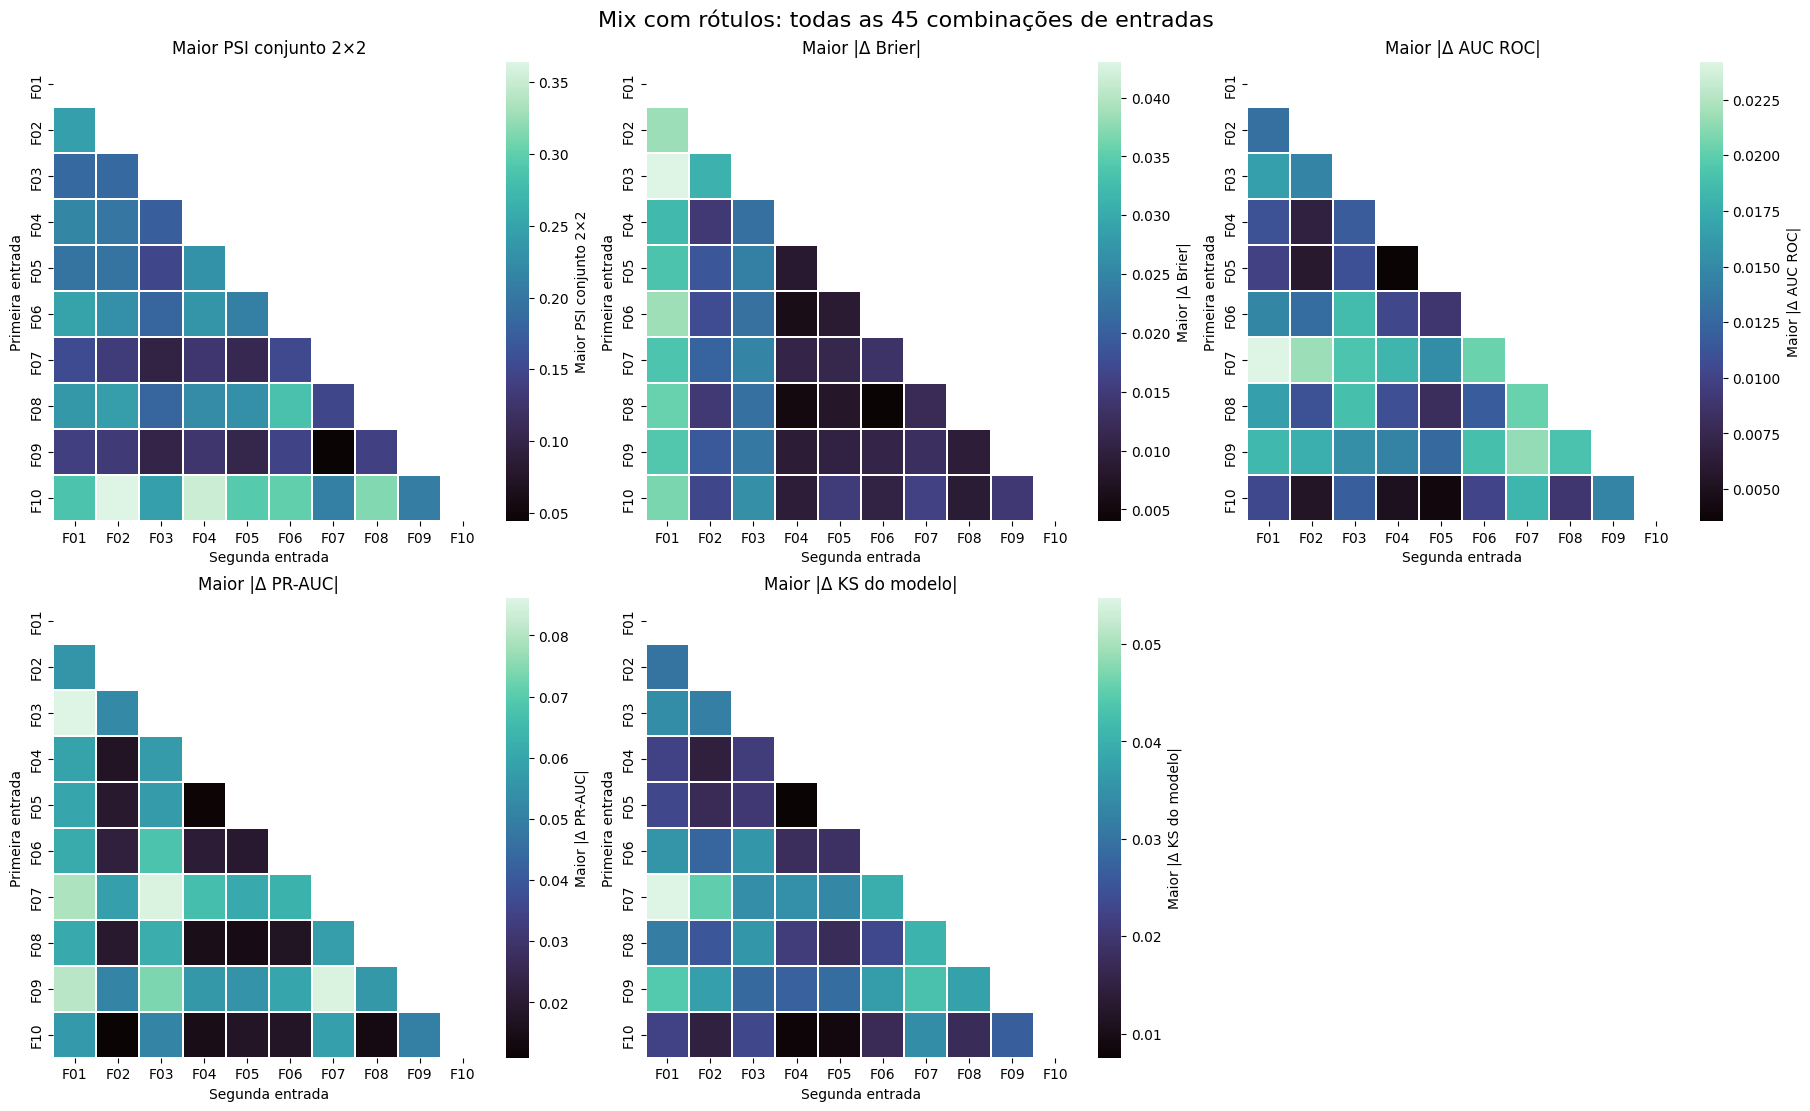

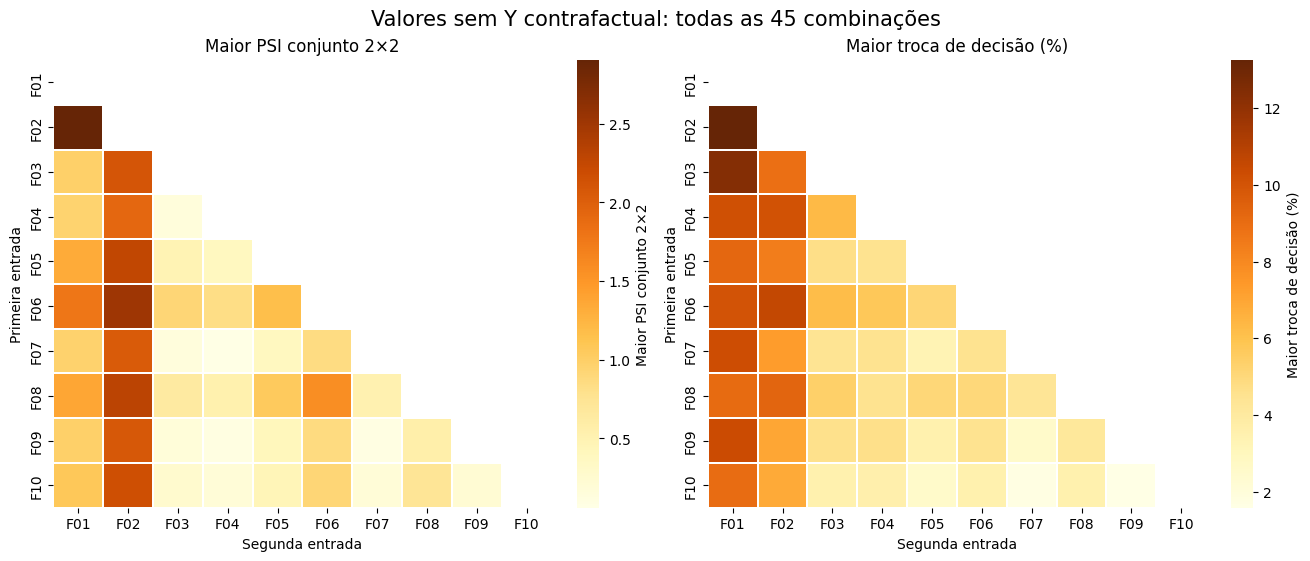

In [4]:
def pair_matrix(frame, column, absolute=False, percent=False):
    values = np.full((10,10), np.nan)
    for (a,b), group in frame.groupby(['variavel_a','variavel_b']):
        i,j = FEATURES.index(a),FEATURES.index(b)
        z = group[column].abs() if absolute else group[column]
        value = z.max() * (100 if percent else 1)
        values[i,j] = values[j,i] = float(value)
    assert np.isfinite(values[~np.eye(10,dtype=bool)]).all()
    return values

mix_maps = [
    ('psi_conjunto_2x2','Maior PSI conjunto 2×2',False),
    ('delta_brier','Maior |Δ Brier|',True),
    ('delta_auc_roc','Maior |Δ AUC ROC|',True),
    ('delta_prauc_trap','Maior |Δ PR-AUC|',True),
    ('delta_ks_modelo','Maior |Δ KS do modelo|',True),
]
fig, axes = plt.subplots(2,3,figsize=(18,11),constrained_layout=True)
for ax,(column,title,absolute) in zip(axes.flat,mix_maps):
    sns.heatmap(pair_matrix(mix_pairs,column,absolute=absolute), mask=np.triu(np.ones((10,10),dtype=bool)),
                cmap='mako', ax=ax, xticklabels=list(ALIASES.values()),yticklabels=list(ALIASES.values()),
                cbar_kws={'label':title}, linewidths=.25)
    ax.set(title=title,xlabel='Segunda entrada',ylabel='Primeira entrada')
axes.flat[-1].axis('off')
fig.suptitle('Mix com rótulos: todas as 45 combinações de entradas',fontsize=16)
mix_map_path = FIGURES/'17_mapa_45_pares_mix.png'
fig.savefig(mix_map_path,dpi=140,bbox_inches='tight')
plt.show()

fig,axes = plt.subplots(1,2,figsize=(13,5.5),constrained_layout=True)
for ax,(column,title,percent) in zip(axes,[
    ('psi_conjunto_2x2','Maior PSI conjunto 2×2',False),
    ('troca_decisao','Maior troca de decisão (%)',True),
]):
    sns.heatmap(pair_matrix(value_pairs,column,percent=percent), mask=np.triu(np.ones((10,10),dtype=bool)),
                cmap='YlOrBr',ax=ax,xticklabels=list(ALIASES.values()),yticklabels=list(ALIASES.values()),
                cbar_kws={'label':title},linewidths=.25)
    ax.set(title=title,xlabel='Segunda entrada',ylabel='Primeira entrada')
fig.suptitle('Valores sem Y contrafactual: todas as 45 combinações',fontsize=15)
value_map_path = FIGURES/'17_mapa_45_pares_valor.png'
fig.savefig(value_map_path,dpi=140,bbox_inches='tight')
plt.show()

## 5. Evolução detalhada de cada par

Os 45 PNGs abaixo têm oito painéis. As cinco curvas azuis/verdes/laranja/vermelhas no bloco **Mix** mostram PSI conjunto e `Δ` Brier, AUC ROC, PR-AUC e KS do modelo. O bloco **Valor** mostra PSI conjunto, decisões que cruzaram 0,50 e movimento absoluto médio do score. A cor indica o sinal solicitado para as duas variáveis; o eixo horizontal vai de 5% a 50% em dez passos. Os resultados do valor usam uma amostra piloto de 5.000 linhas no notebook 09; isso está explicitamente separado do mix rotulado de 22.500 linhas.

Os arquivos têm nomes estáveis `par_F01_F02.png`, etc. O índice guarda **todas** as 45 linhas e pode ser filtrado por qualquer código de variável. Os máximos são descrições da grade simulada, não limites de tolerância nem promessas sobre produção.

In [5]:
pair_index = []
pair_panels = [
    ('mix','psi_conjunto_2x2','PSI conjunto do mix','PSI'),
    ('mix','delta_brier','Δ Brier','Diferença'),
    ('mix','delta_auc_roc','Δ AUC ROC','Diferença'),
    ('mix','delta_prauc_trap','Δ PR-AUC trapezoidal','Diferença'),
    ('mix','delta_ks_modelo','Δ KS do modelo','Diferença'),
    ('valor','psi_conjunto_2x2','PSI conjunto dos valores','PSI'),
    ('valor','troca_decisao','Decisões que cruzaram 0,50','% de linhas'),
    ('valor','mudanca_absoluta_score_media','Movimento absoluto médio do score','Pontos percentuais'),
]
for a,b in EXPECTED_PAIRS:
    m = mix_pairs.loc[(mix_pairs.variavel_a==a)&(mix_pairs.variavel_b==b)]
    v = value_pairs.loc[(value_pairs.variavel_a==a)&(value_pairs.variavel_b==b)]
    fig,axes = plt.subplots(4,2,figsize=(14,15),constrained_layout=True)
    for ax,(family,column,title,ylabel) in zip(axes.flat,pair_panels):
        source = m if family=='mix' else v
        for sign in SIGNS:
            g = source.loc[source.direcao==sign].sort_values('intensidade_pct')
            y = 100*g[column] if family=='valor' and column in ('troca_decisao','mudanca_absoluta_score_media') else g[column]
            ax.plot(g.intensidade_pct,y,'o-',ms=2.5,lw=1.2,color=COLORS[sign],label=sign)
        if column.startswith('delta_'): ax.axhline(0,color='black',lw=.8,ls=':')
        ax.set(title=family.capitalize()+' · '+title,xlabel='Magnitude solicitada para cada entrada (%)',ylabel=ylabel)
    handles,labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,title='Sinais primeira/segunda entrada',loc='lower center',ncol=4,bbox_to_anchor=(.5,-.035))
    fig.suptitle(f'{ALIASES[a]} + {ALIASES[b]} · {a} + {b}',fontsize=13,y=1.015)
    filename=f'par_{ALIASES[a]}_{ALIASES[b]}.png'
    fig.savefig(PAIR_FIGURES/filename,dpi=105,bbox_inches='tight')
    plt.close(fig)
    pair_index.append({
        'codigo_a':ALIASES[a],'variavel_a':a,'codigo_b':ALIASES[b],'variavel_b':b,
        'n_mix':len(m),'n_valor':len(v),
        'psi_mix_max':m.psi_conjunto_2x2.max(),
        'max_abs_delta_brier':m.delta_brier.abs().max(),
        'max_abs_delta_auc_roc':m.delta_auc_roc.abs().max(),
        'max_abs_delta_prauc_trap':m.delta_prauc_trap.abs().max(),
        'max_abs_delta_ks_modelo':m.delta_ks_modelo.abs().max(),
        'psi_valor_max':v.psi_conjunto_2x2.max(),
        'troca_decisao_valor_max_pct':100*v.troca_decisao.max(),
        'figura':f'results/figures/atlas_pares/{filename}',
    })

pair_index = pd.DataFrame(pair_index)
pair_index.to_csv(TABLES/'17_indice_pares.csv',index=False,encoding='utf-8-sig')
assert len(pair_index)==45 and pair_index[['codigo_a','codigo_b']].drop_duplicates().shape[0]==45
assert all((PAIR_FIGURES/f'par_{ALIASES[a]}_{ALIASES[b]}.png').is_file() for a,b in EXPECTED_PAIRS)
display(pair_index.drop(columns=['variavel_a','variavel_b','figura']).round(5))
lines=['| Par | Entradas | Figura com 40 cenários de mix e 40 de valor |','|---|---|---|']
for row in pair_index.itertuples():
    lines.append(f"| {row.codigo_a} + {row.codigo_b} | `{row.variavel_a}` + `{row.variavel_b}` | [Abrir PNG](../{row.figura}) |")
display(Markdown('\n'.join(lines)))
print('Figuras detalhadas:',len(list(PAIR_FIGURES.glob('par_F*_F*.png'))),'| pares esperados:',len(EXPECTED_PAIRS))

,codigo_a,codigo_b,n_mix,n_valor,psi_mix_max,max_abs_delta_brier,max_abs_delta_auc_roc,max_abs_delta_prauc_trap,max_abs_delta_ks_modelo,psi_valor_max,troca_decisao_valor_max_pct
0,F01,F02,40,40,0.24549,0.03848,0.01315,0.05555,0.03011,2.90489,13.26
1,F01,F03,40,40,0.18477,0.04306,0.01659,0.08614,0.03415,0.99118,12.38
2,F01,F04,40,40,0.21747,0.03217,0.01102,0.05914,0.02218,0.95680,10.20
3,F01,F05,40,40,0.19637,0.03353,0.00989,0.05985,0.02295,1.32825,9.20
4,F01,F06,40,40,0.24965,0.03852,0.01476,0.06138,0.03542,1.78885,10.06
5,F01,F07,40,40,0.15368,0.03363,0.02422,0.07933,0.05473,0.96689,10.28
6,F01,F08,40,40,0.23706,0.03561,0.01652,0.06081,0.03158,1.37376,9.10
7,F01,F09,40,40,0.13922,0.03407,0.01839,0.08059,0.04408,0.98297,10.36
8,F01,F10,40,40,0.28580,0.03664,0.01039,0.05652,0.02224,1.07352,9.02
9,F02,F03,40,40,0.18530,0.03094,0.01468,0.05250,0.03172,2.09481,8.90


| Par | Entradas | Figura com 40 cenários de mix e 40 de valor |
|---|---|---|
| F01 + F02 | `RevolvingUtilizationOfUnsecuredLines` + `age` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F02.png) |
| F01 + F03 | `RevolvingUtilizationOfUnsecuredLines` + `NumberOfTime30-59DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F03.png) |
| F01 + F04 | `RevolvingUtilizationOfUnsecuredLines` + `DebtRatio` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F04.png) |
| F01 + F05 | `RevolvingUtilizationOfUnsecuredLines` + `MonthlyIncome` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F05.png) |
| F01 + F06 | `RevolvingUtilizationOfUnsecuredLines` + `NumberOfOpenCreditLinesAndLoans` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F06.png) |
| F01 + F07 | `RevolvingUtilizationOfUnsecuredLines` + `NumberOfTimes90DaysLate` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F07.png) |
| F01 + F08 | `RevolvingUtilizationOfUnsecuredLines` + `NumberRealEstateLoansOrLines` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F08.png) |
| F01 + F09 | `RevolvingUtilizationOfUnsecuredLines` + `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F09.png) |
| F01 + F10 | `RevolvingUtilizationOfUnsecuredLines` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F01_F10.png) |
| F02 + F03 | `age` + `NumberOfTime30-59DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F02_F03.png) |
| F02 + F04 | `age` + `DebtRatio` | [Abrir PNG](../results/figures/atlas_pares/par_F02_F04.png) |
| F02 + F05 | `age` + `MonthlyIncome` | [Abrir PNG](../results/figures/atlas_pares/par_F02_F05.png) |
| F02 + F06 | `age` + `NumberOfOpenCreditLinesAndLoans` | [Abrir PNG](../results/figures/atlas_pares/par_F02_F06.png) |
| F02 + F07 | `age` + `NumberOfTimes90DaysLate` | [Abrir PNG](../results/figures/atlas_pares/par_F02_F07.png) |
| F02 + F08 | `age` + `NumberRealEstateLoansOrLines` | [Abrir PNG](../results/figures/atlas_pares/par_F02_F08.png) |
| F02 + F09 | `age` + `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F02_F09.png) |
| F02 + F10 | `age` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F02_F10.png) |
| F03 + F04 | `NumberOfTime30-59DaysPastDueNotWorse` + `DebtRatio` | [Abrir PNG](../results/figures/atlas_pares/par_F03_F04.png) |
| F03 + F05 | `NumberOfTime30-59DaysPastDueNotWorse` + `MonthlyIncome` | [Abrir PNG](../results/figures/atlas_pares/par_F03_F05.png) |
| F03 + F06 | `NumberOfTime30-59DaysPastDueNotWorse` + `NumberOfOpenCreditLinesAndLoans` | [Abrir PNG](../results/figures/atlas_pares/par_F03_F06.png) |
| F03 + F07 | `NumberOfTime30-59DaysPastDueNotWorse` + `NumberOfTimes90DaysLate` | [Abrir PNG](../results/figures/atlas_pares/par_F03_F07.png) |
| F03 + F08 | `NumberOfTime30-59DaysPastDueNotWorse` + `NumberRealEstateLoansOrLines` | [Abrir PNG](../results/figures/atlas_pares/par_F03_F08.png) |
| F03 + F09 | `NumberOfTime30-59DaysPastDueNotWorse` + `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F03_F09.png) |
| F03 + F10 | `NumberOfTime30-59DaysPastDueNotWorse` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F03_F10.png) |
| F04 + F05 | `DebtRatio` + `MonthlyIncome` | [Abrir PNG](../results/figures/atlas_pares/par_F04_F05.png) |
| F04 + F06 | `DebtRatio` + `NumberOfOpenCreditLinesAndLoans` | [Abrir PNG](../results/figures/atlas_pares/par_F04_F06.png) |
| F04 + F07 | `DebtRatio` + `NumberOfTimes90DaysLate` | [Abrir PNG](../results/figures/atlas_pares/par_F04_F07.png) |
| F04 + F08 | `DebtRatio` + `NumberRealEstateLoansOrLines` | [Abrir PNG](../results/figures/atlas_pares/par_F04_F08.png) |
| F04 + F09 | `DebtRatio` + `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F04_F09.png) |
| F04 + F10 | `DebtRatio` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F04_F10.png) |
| F05 + F06 | `MonthlyIncome` + `NumberOfOpenCreditLinesAndLoans` | [Abrir PNG](../results/figures/atlas_pares/par_F05_F06.png) |
| F05 + F07 | `MonthlyIncome` + `NumberOfTimes90DaysLate` | [Abrir PNG](../results/figures/atlas_pares/par_F05_F07.png) |
| F05 + F08 | `MonthlyIncome` + `NumberRealEstateLoansOrLines` | [Abrir PNG](../results/figures/atlas_pares/par_F05_F08.png) |
| F05 + F09 | `MonthlyIncome` + `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F05_F09.png) |
| F05 + F10 | `MonthlyIncome` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F05_F10.png) |
| F06 + F07 | `NumberOfOpenCreditLinesAndLoans` + `NumberOfTimes90DaysLate` | [Abrir PNG](../results/figures/atlas_pares/par_F06_F07.png) |
| F06 + F08 | `NumberOfOpenCreditLinesAndLoans` + `NumberRealEstateLoansOrLines` | [Abrir PNG](../results/figures/atlas_pares/par_F06_F08.png) |
| F06 + F09 | `NumberOfOpenCreditLinesAndLoans` + `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F06_F09.png) |
| F06 + F10 | `NumberOfOpenCreditLinesAndLoans` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F06_F10.png) |
| F07 + F08 | `NumberOfTimes90DaysLate` + `NumberRealEstateLoansOrLines` | [Abrir PNG](../results/figures/atlas_pares/par_F07_F08.png) |
| F07 + F09 | `NumberOfTimes90DaysLate` + `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F07_F09.png) |
| F07 + F10 | `NumberOfTimes90DaysLate` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F07_F10.png) |
| F08 + F09 | `NumberRealEstateLoansOrLines` + `NumberOfTime60-89DaysPastDueNotWorse` | [Abrir PNG](../results/figures/atlas_pares/par_F08_F09.png) |
| F08 + F10 | `NumberRealEstateLoansOrLines` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F08_F10.png) |
| F09 + F10 | `NumberOfTime60-89DaysPastDueNotWorse` + `NumberOfDependents` | [Abrir PNG](../results/figures/atlas_pares/par_F09_F10.png) |

Figuras detalhadas: 45 | pares esperados: 45


## 6. Como interpretar e reutilizar

1. Escolha a entrada ou o par no índice e abra sua figura. Leia primeiro o **percentual solicitado**, depois o **PSI realizado**. Percentual e PSI não têm a mesma unidade.
2. Para **mix**, leia as quatro curvas de `Δ` e veja em qual direção e intensidade a resposta muda. Consulte os CSVs do 09 para prevalência, ESS, recall e precisão. Se a prevalência muda, PR-AUC e Brier podem mudar também por composição; considere isso na interpretação.
3. Para **valor**, leia PSI, deslocamento do score, troca de decisão e, no CSV, a mudança realizada e valores fora do suporte. **Não** descreva essas curvas como AUC ou Brier de um novo mundo sem observar os respectivos rótulos contrafactuais.
4. Para aplicar em outro modelo, substitua o manifesto, as dez entradas e os quatro CSVs pelo resultado de uma grade equivalente; mantenha o mesmo esquema de colunas ou adapte as funções de leitura. Defina bins do PSI na população de referência, preserve as unidades e a semântica de cada variável, mantenha o modelo congelado e verifique o suporte estatístico de cenários extremos.

O atlas é uma análise **exploratória** de cenários selecionados. Nenhum valor de PSI, `|Δ|` ou porcentagem é transformado automaticamente em alerta ou limite de aprovação. Para afirmar uma tolerância operacional, seria necessário definir com especialistas o impacto aceitável, a população e o horizonte de monitoramento, e validá-lo com dados rotulados posteriores.